# How did the 2025 U.S. Tariffs impact Imports?
Cole Mitchell

[Project Website](https://ColeMitchell1.github.io)

## Project Goals:

In 2025 the United States raised tariffs on imports from multiple trading partners including China, Canada and Mexico. Supporters argue tariffs bring production back to the USA, while critics say they lead to price increases and trade disputes. The goal of this project is to test the effects of tariffs. Did U.S. imports shrink, or did they move to other countries? To track this, I will be looking at the top 10 partners' shares of total U.S. imports before and after tariff implementation. I will also compare those changes with customs revenue.

## Project Questions:
1. Did China's share of total U.S. imports fall after the tariffs, and which partners gained?
2. After accounting for exchange rate and import prices, is the change in China's share still there?
3. How much customs revenue did the tariffs generate?

All the data used comes from FRED (The Federal Reserve Bank of St. Louis) which republishes government data: Imports from the U.S. Census Bureau, customs duties from the Bureau of Economic Analysis, import prices from the Bureau of Labor Statistics, and the dollar index from the Federal Reserve Board.

For the data, I will be using 2018 onward to cover both the 2018-2019 tariffs and the 2025 tariffs.



Collaboration Plan:

As a Master's student, I will be working alone and will not need a collaboration plan.

# Project Dataset 1



## Imports by Partner Country
[IMPCH on FRED](https://fred.stlouisfed.org/series/IMPCH).
Each series gives monthly U.S. imports of goods (millions of dollars, not seasonally adjusted) from one country, published by the U.S. Census Bureau and republished by FRED. I loaded each CSV directly from FRED's download link, downloaded 21 partners, ranked them by total 2024 imports, and kept the top 10. I then use the top 10 to measure where imports come from and to answer the question "Did China's share of U.S. imports fall after the tariffs, and who gained?"

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 21 canidate partners and their matching FRED id's
Candidates = {
    'IMPCH': 'China', 'IMPCA': 'Canada', 'IMPMX': 'Mexico', 'IMPJP': 'Japan',
    'IMPGE': 'Germany', 'IMPKR': 'South Korea', 'IMPUK': 'United Kingdom',
    'IMPFR': 'France', 'IMP5520': 'Vietnam', 'IMP5330': 'India',
    'IMP4190': 'Ireland', 'IMP5830': 'Taiwan', 'IMP4759': 'Italy',
    'IMP4419': 'Switzerland', 'IMP5490': 'Thailand', 'IMP5570': 'Malaysia',
    'IMP4210': 'Netherlands', 'IMP3510': 'Brazil', 'IMP5590': 'Singapore',
    'IMP5081': 'Israel', 'IMP5600': 'Indonesia'}

def load_fred(series_id, value_name):
  #Download one FRED series as a CSV
  url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
  df = pd.read_csv(url, na_values='.')
  df.columns = ['Date', value_name]
  df['Date'] = pd.to_datetime(df['Date'])
  return df

#download each candidate
frames, failed = [], []
for sid, country in Candidates.items():
  try:
      d = load_fred(sid, 'Imports_MUSD')
      d['Country'] = country
      frames.append(d)
  except Exception:
        failed.append((sid, country))
print("Failed to load: ", failed)
df_Cand = pd.concat(frames, ignore_index=True)
display(df_Cand.head())
display(df_Cand.dtypes)


Failed to load:  []


,Date,Imports_MUSD,Country
0,1985-01-01,293.1,China
1,1985-02-01,281.0,China
2,1985-03-01,293.0,China
3,1985-04-01,283.3,China
4,1985-05-01,295.1,China


,0
Date,datetime64[ns]
Imports_MUSD,float64
Country,object


All candidates downloaded. The dtypes are all correct, so no conversion is needed. Next, I will rank the countries by total 2024 imports.

In [2]:
#Total 2024 imports for each country
rank_2024 = (df_Cand[df_Cand['Date'].dt.year == 2024]
             .groupby('Country')['Imports_MUSD'].sum()
             .sort_values(ascending=False))
display(rank_2024.round(0))

,Imports_MUSD
Country,
Mexico,503110.0
China,440319.0
Canada,411772.0
Germany,160307.0
Japan,147117.0
Vietnam,136318.0
South Korea,131457.0
Taiwan,116285.0
Ireland,103264.0


This table ranked all countries by 2024 imports. I will keep just the top 10 trade partners.

In [3]:
#Keep the 10 largest 2024 partners from 2018 onward
Top_n = 10
top_countries = rank_2024.head(Top_n).index.tolist()
df_Imports = df_Cand[df_Cand['Country'].isin(top_countries)
& (df_Cand['Date'] >= '2018-01-01')].copy()

print(top_countries)
print(df_Imports.groupby('Country')['Date'].count())

['Mexico', 'China', 'Canada', 'Germany', 'Japan', 'Vietnam', 'South Korea', 'Taiwan', 'Ireland', 'India']
Country
Canada         105
China          105
Germany        105
India          105
Ireland        105
Japan          105
Mexico         105
South Korea    105
Taiwan         105
Vietnam        105
Name: Date, dtype: int64


I trim the data to 2018 onwards so the sample includes the 2018-19 tariffs. Each country has the same 105 months.

In [4]:
#Total U.S. imports from all countries
df_World = load_fred('IMP0004', 'World_MUSD')
df_World = df_World[df_World['Date'] >= '2018-01-01']

display(df_World.tail())
display(df_World.dtypes)

,Date,World_MUSD
448,2026-05-01,314507.031641
449,2026-06-01,306668.424109
450,2026-07-01,318679.198314
451,2026-08-01,336228.671338
452,2026-09-01,344196.556528


,0
Date,datetime64[ns]
World_MUSD,float64


This series shows the total U.S. imports of goods from all countries. I can use this to find the true share of U.S. imports by dividing each country's imports by it. The data runs through September 2026, and the Dtypes are correct.

In [5]:
#Tidy check
#Count NaNs in every column
display(df_Imports.isna().sum())

#Duplicates
print(df_Imports.duplicated(subset=['Date', 'Country']).sum(), "duplicate country-months")
#data types:
display(df_Imports.dtypes)

,0
Date,0
Imports_MUSD,0
Country,0


0 duplicate country-months


,0
Date,datetime64[ns]
Imports_MUSD,float64
Country,object


The data is tidy, each row is one country in one month, each column is one variable, and each value has its own cell.

The main cleaning involved:
- Converting FRED's '.' placeholder to NaN when loading
-Labeling each series with its country name so the downloads could be combined into one table
- Filtering the top 10 countries from 2018 onward.

In [6]:
#Attach each month's total U.S. imports to every country/month row
df_Imports = df_Imports.merge(df_World, on='Date', how='left')


I merge the monthly world total onto the country table using Date as the key and I used a left merge so no country rows are dropped.

In [7]:
#Share = countrys imports / total U.S. imports in the same month
df_Imports['Share'] = df_Imports['Imports_MUSD'] / df_Imports['World_MUSD']




Dollar amounts are difficult to compare over time because total U.S. imports change with the economy. Dividing each country's imports by the world total gives its share of U.S. imports.

In [8]:
##Post/China Indicators

#Post = 1 for months on or after April 2025
df_Imports['Post'] = (df_Imports['Date'] >= '2025-04-1').astype(int)

#China = 1
df_Imports['China'] = (df_Imports['Country'] == 'China').astype(int)

print(df_Imports['Post'].value_counts())
print(df_Imports['China'].value_counts())

Post
0    870
1    180
Name: count, dtype: int64
China
0    945
1    105
Name: count, dtype: int64


These indicators set up the before/after comparison used later. `Post` marks months from April 2025 onward. I chose April 2025 because that is when broad new tariffs were announced and took effect: [Executive Order 14257](https://www.whitehouse.gov/presidential-actions/2025/04/regulating-imports-with-a-reciprocal-tariff-to-rectify-trade-practices-that-contribute-to-large-and-persistent-annual-united-states-goods-trade-deficits/) set a 10% baseline tariff on all trading partners starting April 5, with higher country specific rates starting April 9. `China` marks China's rows so its change can be compared with the other nine partners.

## Chart 1: Top 10 Import Partners in 2024

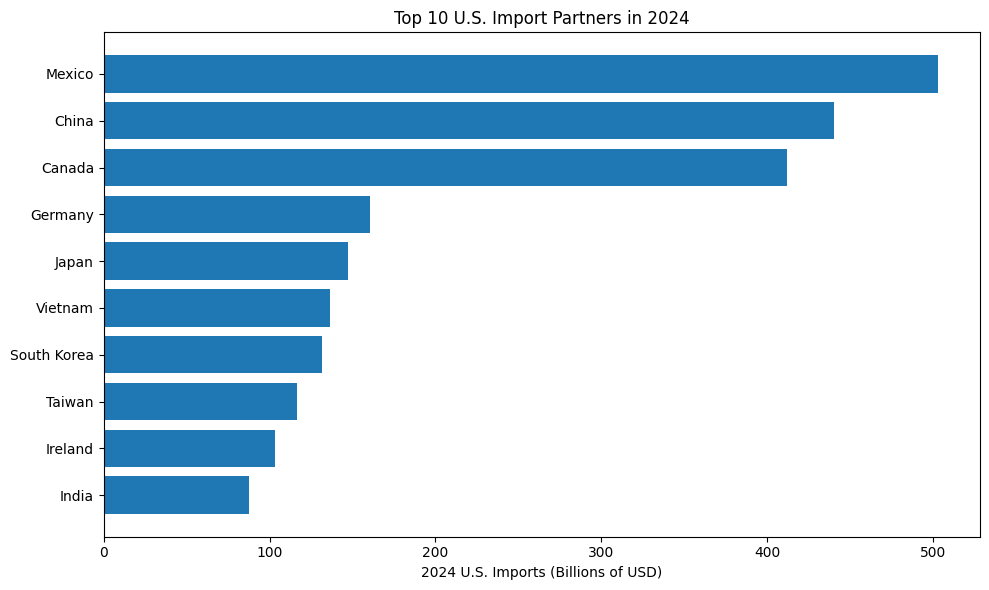

In [9]:
#Bar chart of the top 10 partners by 2024 imports (In Billions)
#Convert millions to billions
top10 = rank_2024.head(10) / 1000
top10 = top10.sort_values()

#Chart
plt.figure(figsize=(10, 6))
plt.barh(top10.index, top10.values)
plt.xlabel('2024 U.S. Imports (Billions of USD)')
plt.title('Top 10 U.S. Import Partners in 2024')
plt.tight_layout()
plt.show()

This bar chart ranks the ten countries by 2024 imports. Mexico, China, and Canada are the largest partners at about \$500, \$440, and \$410 billion. Each more than twice the size of fourth place Germany (about \$160 billion).

## Chart 2: Import Shares Over Time

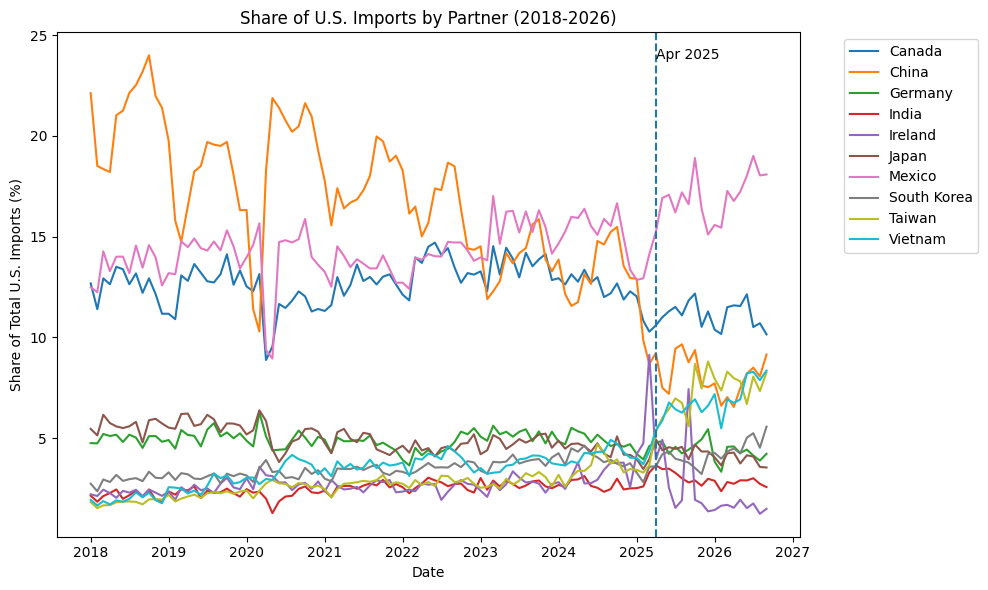

In [10]:
##Shares Over Time
#Line Chart of each countrys share of total U.S. imports over time

#Pivot, each country is its own column
shares = df_Imports.pivot(index='Date', columns='Country', values='Share')

#Chart
plt.figure(figsize=(10, 6))
for country in shares.columns:
  plt.plot(shares.index, shares[country] * 100, label=country)

#Dashed line at the Post period
plt.axvline(pd.Timestamp('2025-04-01'), linestyle='--')
plt.text(pd.Timestamp('2025-04-1'), plt.ylim()[1] * .97, 'Apr 2025', va='top')

plt.ylabel('Share of Total U.S. Imports (%)')
plt.xlabel('Date')
plt.title('Share of U.S. Imports by Partner (2018-2026)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()




This chart shows each country's monthly share of total U.S. imports with a dashed line at April 2025. China's share was around 20% in 2018 and slowly decreased to around 15% by 2024, then fell sharply to under 10% after early 2025. Over the same period, Mexico rose from about 15% to 18%, and Vietnam and Taiwan both rose from under 5% to about 8%. This chart suggests that imports shifted away from China towards other partners, especially after April 2025.

## Chart 3: Average Share Before vs. After April 2025

In [11]:
##Before/After Average Share Table
#Average monthly share for each country before vs. after April
avg = df_Imports.groupby(['Country', 'Post'])['Share'].mean().unstack() * 100
avg.columns = ['Before_Pct', 'After_Pct']
#Change in Percentage points
avg['Change_pts'] = avg['After_Pct'] - avg['Before_Pct']

#Sort
display(avg.sort_values('Change_pts').round(2))

,Before_Pct,After_Pct,Change_pts
Country,,,
China,16.84,8.09,-8.76
Canada,12.68,11.11,-1.57
Japan,4.98,4.19,-0.78
Germany,4.89,4.41,-0.48
Ireland,2.77,2.31,-0.46
India,2.48,2.95,0.47
South Korea,3.43,4.24,0.81
Mexico,14.24,16.95,2.71
Vietnam,3.37,6.84,3.47


This table compares each countries average monthly share of U.S. imports before April 2025 with its average after, and the change in percentage points. China has the largest decline of -8.76. Canada and Japan also lost share, while Taiwan, Mexico, and Vietnam were the biggest gainers. This supports the claim that imports were being redirected to other countries.

## Chart 4: China's Share Before vs. After April 2025

<Figure size 1000x600 with 0 Axes>

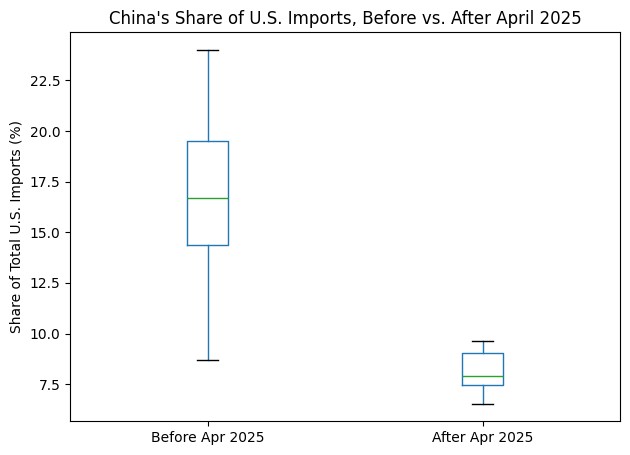

,count,mean,std,min,25%,50%,75%,max
Period,,,,,,,,
Before Apr 2025,87.0,16.84,3.4,8.68,14.38,16.68,19.53,24.00
After Apr 2025,18.0,8.09,1.0,6.55,7.48,7.89,9.05,9.65


In [12]:
#Boxplot of China's monthly share before vs. after April 2025
china = df_Imports[df_Imports['Country'] == 'China'].copy()
china['Share_Pct'] = china['Share'] * 100
china['Period'] = china['Post'].map({0: 'Before Apr 2025', 1: "After Apr 2025"})

#Plot
plt.figure(figsize=(10, 6))
china['Period'] = pd.Categorical(china['Period'],
 ['Before Apr 2025', 'After Apr 2025'], ordered=True)
china.boxplot(column='Share_Pct', by='Period', grid=False)
#Remove Pandas super title
plt.suptitle('')
plt.title("China's Share of U.S. Imports, Before vs. After April 2025")
plt.xlabel('')
plt.ylabel('Share of Total U.S. Imports (%)')
plt.tight_layout()
plt.show()

#Summary
display(china.groupby('Period', observed=True)['Share_Pct'].describe().round(2))

This boxplot shows the spread of China's monthly import share before and after April 2025. The median share was 16.68% before and 7.89% after. China's best month after April 2025 (9.65%) is only slightly above its worst month before (8.68%), so the two periods barely overlap.

# Project Dataset 2
Source: FRED (https://fred.stlouisfed.org/series/B235RC1Q027SBEA) from the Bureau of Economic Analysis.

For my second dataset, I am using Federal government customs duties (tariff revenue), reported quarterly in billions of dollars at a seasonally adjusted annual rate. This dataset shows how much tariff money the U.S. government actually collected. Dividing duties by total imports gives an effective tariff rate. This measures how large tariffs were in practice. To match dataset 1, I start in 2018.


In [13]:
#Load FRED data
df_Duties = load_fred('B235RC1Q027SBEA', 'Customs_Duties_BUSD')

#Limit to 2018
df_Duties = df_Duties[df_Duties['Date'] >= '2018-01-01'].copy()

#Check first and last rows, dtypes and possible missing values
display(df_Duties.head())
display(df_Duties.tail(8))
display(df_Duties.dtypes)
print(df_Duties['Customs_Duties_BUSD'].isna().sum())

,Date,Customs_Duties_BUSD
236,2018-01-01,41.337
237,2018-04-01,46.657
238,2018-07-01,53.244
239,2018-10-01,71.898
240,2019-01-01,75.735


,Date,Customs_Duties_BUSD
263,2024-10-01,89.104
264,2025-01-01,103.660
265,2025-04-01,270.592
266,2025-07-01,333.750
267,2025-10-01,366.651
268,2026-01-01,326.223
269,2026-04-01,306.398
270,2026-07-01,275.296


,0
Date,datetime64[ns]
Customs_Duties_BUSD,float64


0


The data has 35 quarters from Q1 2018- Q3 2026. Duties jump from about \$104 billion in Q1 2025 to about \$271 billion in Q2 2025, peak at about \$367 billion in Q4 2025, then fall to about \$275 billion by Q3 2026.

## Converting Imports to Quarterly

In [14]:
#Add monthly total U.S. imports into quarters
#QS = Quarter start date
q_imports = (df_World.set_index('Date')['World_MUSD']
             .resample('QS').agg(['sum', 'count']).reset_index())
q_imports.columns = ['Date', 'Quarter_Imports_MUSD', 'Months']

#Convert millions -> billions
q_imports['Quarter_Imports_BUSD'] = q_imports['Quarter_Imports_MUSD'] / 1000

#Check first last row, incomplete quarters
display(q_imports.head())
display(q_imports.tail())
print(len(q_imports), "quarters")
print((q_imports['Months'] !=3).sum(), "Incomplete Quarters")

,Date,Quarter_Imports_MUSD,Months,Quarter_Imports_BUSD
0,2018-01-01,625652.186963,3,625.652187
1,2018-04-01,628202.069384,3,628.202069
2,2018-07-01,640084.637409,3,640.084637
3,2018-10-01,642206.379922,3,642.206380
4,2019-01-01,629087.383662,3,629.087384


,Date,Quarter_Imports_MUSD,Months,Quarter_Imports_BUSD
30,2025-07-01,810992.643239,3,810.992643
31,2025-10-01,808212.508544,3,808.212509
32,2026-01-01,856545.668336,3,856.545668
33,2026-04-01,923514.339835,3,923.514340
34,2026-07-01,999104.426180,3,999.104426


35 quarters
0 Incomplete Quarters


Customs duties are reported quarterly, while import data is monthly. I add up total U.S. imports within each quarter to combine the two datasets on the same dates. I also convert millions to billions to match the units, and check that each quarter has all three months.

## Effective Tariff Rate

In [15]:
#Combine duties and quarterly imports on the quarter start date
df_Quarterly = df_Duties.merge(
    q_imports[['Date', 'Quarter_Imports_BUSD']], on='Date', how='left')

#Duties are an annual rate. Convert quarterly imports to annual rate
df_Quarterly['Annual_Imports_BUSD'] = df_Quarterly['Quarter_Imports_BUSD'] * 4

#Effective tariff rate % = duties collected / value of imports
df_Quarterly['Eff_Tariff_Rate'] = (df_Quarterly['Customs_Duties_BUSD']
                                   / df_Quarterly['Annual_Imports_BUSD'] * 100)

display(df_Quarterly.head())
display(df_Quarterly.tail(8))
display(df_Quarterly.dtypes)


,Date,Customs_Duties_BUSD,Quarter_Imports_BUSD,Annual_Imports_BUSD,Eff_Tariff_Rate
0,2018-01-01,41.337,625.652187,2502.608748,1.651756
1,2018-04-01,46.657,628.202069,2512.808278,1.856767
2,2018-07-01,53.244,640.084637,2560.338550,2.079569
3,2018-10-01,71.898,642.206380,2568.825520,2.798867
4,2019-01-01,75.735,629.087384,2516.349535,3.009717


,Date,Customs_Duties_BUSD,Quarter_Imports_BUSD,Annual_Imports_BUSD,Eff_Tariff_Rate
27,2024-10-01,89.104,844.847346,3379.389384,2.636689
28,2025-01-01,103.660,985.393926,3941.575705,2.629913
29,2025-04-01,270.592,809.911515,3239.646059,8.352517
30,2025-07-01,333.750,810.992643,3243.970573,10.288318
31,2025-10-01,366.651,808.212509,3232.850034,11.341417
32,2026-01-01,326.223,856.545668,3426.182673,9.521471
33,2026-04-01,306.398,923.514340,3694.057359,8.294349
34,2026-07-01,275.296,999.104426,3996.417705,6.888569


,0
Date,datetime64[ns]
Customs_Duties_BUSD,float64
Quarter_Imports_BUSD,float64
Annual_Imports_BUSD,float64
Eff_Tariff_Rate,float64


I merge quarterly duties with quarterly imports and divide duties by imports to get the effective tariff rate. This shows how much tariff money was actually collected per dollar of imports. Duties are reported at an annual rate, so I multiply quarterly imports by 4 to put both on the same scale.

The effective tariff rate was about 1.7% in early 2018 and rose to about 3% by early 2019. It jumped to 8.4% in Q2 2025 and peaked at 11.3% in Q4 2025 before falling back down by Q3 2026.

## Chart 5: Customs Duties and the Effective Tariff Rate

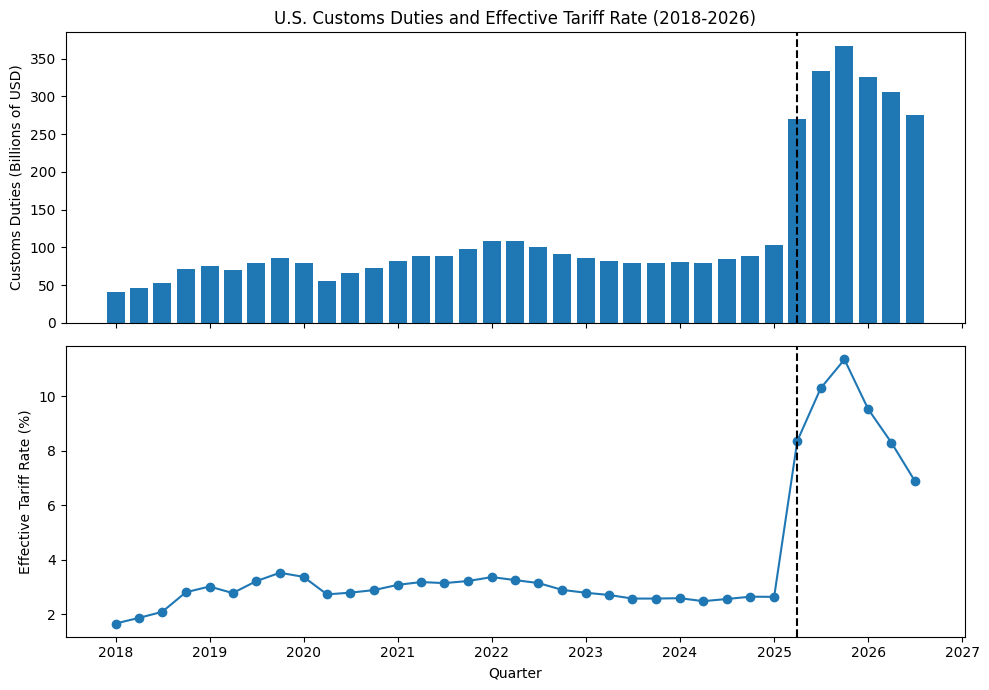

In [16]:
#Two stacked panels
#Top = Dollars collected, bottom = Effective tariff rate
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

#Top panel = Quarterly customs duties
ax1.bar(df_Quarterly['Date'], df_Quarterly['Customs_Duties_BUSD'],
        width=70,)
ax1.set_ylabel('Customs Duties (Billions of USD)')
ax1.set_title('U.S. Customs Duties and Effective Tariff Rate (2018-2026)')

#Bottom panel = Effective tariff rate
ax2.plot(df_Quarterly['Date'], df_Quarterly['Eff_Tariff_Rate'],
         marker='o')
ax2.set_ylabel('Effective Tariff Rate (%)')
ax2.set_xlabel('Quarter')

#Dashed line at the start of the post period for both panels
for ax in (ax1, ax2):
  ax.axvline(pd.Timestamp('2025-04-01'), color='black', linestyle='--')

plt.tight_layout()
plt.show()

The top panel shows how much customs revenue the government collected each quarter, and the bottom shows that revenue as a percentage of imports. Duties stayed between around \$40 Billion and \$110 billion per year from 2018-2024, then rose to over \$250 billion in Q2 2025 and over \$350 billion in Q4 2025. The effective rate shows a similar trend, staying between 2% and 4% from 2018-2024 then jumping to 8-11% in 2025. The data also shows a drop in both duties and rate in 2026.  

# Dataset 3: Dollar index and Import Prices

Sources: (https://fred.stlouisfed.org/series/TWEXBGSMTH), The Federal Reserve Board's broad U.S. dollar index (Published through FRED), and (https://fred.stlouisfed.org/series/IR), the BLS import price index for all commodities (both monthly)

I use these because a country's share of U.S. imports may change for reasons other than tariffs. A stronger U.S. dollar makes foreign goods cheaper, and rising import prices change the dollar value of imports. These two variables allow the model to separate those effects from the tariff effect.


In [17]:
#U.S. dollar index (FRED) and import price index monthly
df_Dollar = load_fred('TWEXBGSMTH', 'Dollar_Index')
df_ImpPrice = load_fred('IR', 'Import_Price_Index')

#Combine on date
df_Macro = df_Dollar.merge(df_ImpPrice, on='Date', how='outer')

#Dataset to 2018
df_Macro = df_Macro[df_Macro['Date'] >= '2018-01-01'].copy()

#Checks
display(df_Macro.tail(8))
display(df_Macro.isna().sum())
print(len(df_Macro), "months")


,Date,Dollar_Index,Import_Price_Index
522,2026-03-01,119.9199,144.8
523,2026-04-01,119.0363,148.1
524,2026-05-01,118.7792,150.7
525,2026-06-01,120.0835,150.3
526,2026-07-01,120.5970,149.7
527,2026-08-01,118.8512,150.5
528,2026-09-01,119.2152,152.2
529,2026-10-01,121.4781,NaN


,0
Date,0
Dollar_Index,0
Import_Price_Index,2


106 months


## Data Alignment

The import price index has two missing months. The first is October 2026, which has not been published yet. The dollar index has data through October 2026, but the import price index ends in September 2026. I trim the table to September 2026 to match the rest of the data, which removes the missing row.

The other missing month is October 2025. Rather than drop that month, I fill it by linear interpolation, which sets it halfway between September and November 2025. After these steps the table has 105 months and no missing values.

In [18]:
#Match the end date of the import data
df_Macro = df_Macro[df_Macro['Date'] <= '2026-09-01'].copy()

#Find missing months
missing = df_Macro[df_Macro['Import_Price_Index'].isna()]['Date']
print(missing)

#Fill the missing month by linear interpolation
df_Macro['Import_Price_Index'] = df_Macro['Import_Price_Index'].interpolate()

#Checks
print(df_Macro.isna().sum(), "Missing values")
print(len(df_Macro), "months")
display(df_Macro.dtypes)


517   2025-10-01
Name: Date, dtype: datetime64[ns]
Date                  0
Dollar_Index          0
Import_Price_Index    0
dtype: int64 Missing values
105 months


,0
Date,datetime64[ns]
Dollar_Index,float64
Import_Price_Index,float64


## Adding the Macro variables

I merge the dollar index and import price index onto the country table using Date as the key. A left merge keeps all country-month rows, and I check that the merge adds no missing values.

In [19]:
#Attach the dollar index and import price index to each country-month row
#how = left, keep all country-month rows
df_Imports = df_Imports.merge(df_Macro, on='Date', how='left')

#Checks
print(len(df_Imports), "rows")
print(df_Imports[['Dollar_Index', 'Import_Price_Index']].isna().sum())
display(df_Imports.head())

1050 rows
Dollar_Index          0
Import_Price_Index    0
dtype: int64


,Date,Imports_MUSD,Country,World_MUSD,Share,Post,China,Dollar_Index,Import_Price_Index
0,2018-01-01,45681.310362,China,206553.230328,0.221160,0,1,108.3568,126.5
1,2018-02-01,38956.173961,China,210566.131780,0.185007,0,1,107.6501,126.8
2,2018-03-01,38273.829291,China,208532.824855,0.183539,0,1,107.9472,126.5
3,2018-04-01,38227.767574,China,209993.396351,0.182043,0,1,107.9434,127.1
4,2018-05-01,43866.578304,China,208636.645803,0.210253,0,1,111.0470,128.2


## Chart 6: China's share vs. the dollar index

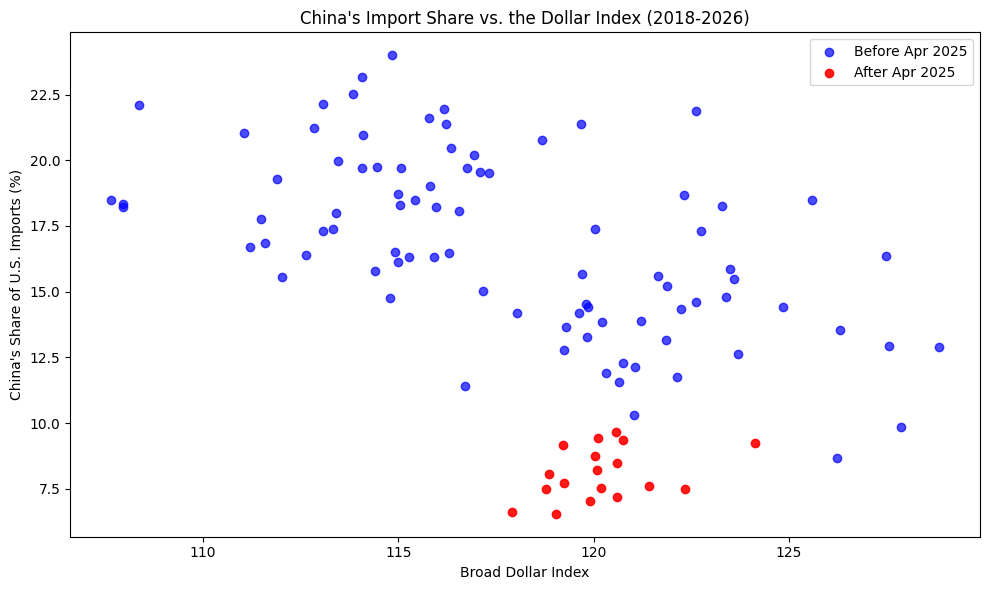

-0.56


In [20]:
#Scatter plot of China's monthly import share against the dollar index
china = df_Imports[df_Imports['China'] ==1 ]
before = china[china['Post'] == 0]
after = china[china['Post'] == 1]

plt.figure(figsize=(10, 6))
#Color by whether the month is before or after April 2025
plt.scatter(before['Dollar_Index'], before['Share'] * 100,
            color='blue', alpha=.7, label='Before Apr 2025')
plt.scatter(after['Dollar_Index'], after['Share'] * 100,
            color='red', alpha=.9, label='After Apr 2025')

plt.xlabel('Broad Dollar Index')
plt.ylabel("China's Share of U.S. Imports (%)")
plt.title("China's Import Share vs. the Dollar Index (2018-2026)")
plt.legend()
plt.tight_layout()
plt.show()

#Correlation between China's share and the dollar index before April 2025
print(round(before['Share'].corr(before['Dollar_Index']), 2))

Each dot represents one month. Blue dots are months before April 2025 and red dots are months after. Before April 2025, China's share and the dollar index have a moderate negative relationship (-0.56). Months with a stronger dollar tend to have a lower China share. This shows correlation but not causation, since China's share was trending down while the dollar was trending up. The months after April 2025 show a clearer pattern, they all sit at about 6%-10%, below nearly all of the blue dots at similar dollar levels. This suggests the drop in China's share after April 2025 is not explained by the dollar alone.

## Chart 7: Correlations with China's Import Share


In [21]:
#Correlations between China's share and the other variables
china = df_Imports[df_Imports['China'] == 1]
corr = china[['Share', 'Dollar_Index', 'Import_Price_Index', 'Post']].corr().round(2)
display(corr)

,Share,Dollar_Index,Import_Price_Index,Post
Share,1.00,-0.51,-0.68,-0.73
Dollar_Index,-0.51,1.00,0.54,0.20
Import_Price_Index,-0.68,0.54,1.00,0.47
Post,-0.73,0.20,0.47,1.00


This table shows how strongly each variable moves with China's monthly import share. Share has a correlation of -0.51 with the dollar index, -0.68 with the import price index, and -0.73 with the Post indicator. Post is the strongest which fits the pattern in Charts 4 and 6. The dollar index and import price index are correlated with each other (0.54), so they partly overlap. The import price index looks strongly related to China's share partly because prices rose over 2018-2026 while China's share fell over the same period.

## Model Ideas

### Model 1: Did China's import share fall more than other partners' after April 2025

**Dependent Variable:** `Share`, each country's monthly share of total U.S. imports.

**Independent Variables:**
- `China x Post`: This measures how much more China's share changed after April 2025 than the other nine partners' shares did. I expect this to be negative.
- `Post`, `Dollar_Index`, and `Import_Price_Index`: Controls for the post-tariff period and for macroeconomic conditions.
- Country fixed effects, so each country has its own baseline share.

**Methodology:** A difference-in-differences style panel regression on the 1,050 country-month rows with standard errors clustered by country. The other nine partners will act as the comparison group. I judge the model by the size and confidence interval of `China x Post`. As a robustness check, I add a China specific time trend since China's share was already falling before 2025.

**Potential Limitations:** Ten countries is a small number of groups, and other 2025 events may have affected trade at the same time, so the results show an association, not proof of cause.

### Model 2: Can the effective tariff rate be predicted?

**Dependent Variable:** `Eff_Tariff_Rate`, customs duties as a percentage of annualized imports.

**Independent Variables:** `Post`, Chinas average import share in the quarter, and quarterly averages of `Dollar_Index` and `Import_Price_Index`.

**Methodology:** A linear regression on the 35 quarterly observations with a time-based split: Train on Q1 2018 to Q4 2025 and test on Q1 to Q3 2026. The baseline is a forecast that repeats the previous quarter's rate. I compare the two using mean absolute error and root mean squared error.

**Potential Limitations:** With only 35 quarters, the test set is only 3 quarters, so the results are exploratory and could be due to chance. The model may also fail to beat the simple baseline.

In [22]:
from google.colab import drive
drive.mount('/content/drive')
!jupyter nbconvert --to html "/content/drive/MyDrive/Colab Notebooks/Cole Mitchell Milestone 2.ipynb"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[NbConvertApp] Converting notebook /content/drive/MyDrive/Colab Notebooks/Cole Mitchell Milestone 2.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 5 image(s).
[NbConvertApp] Writing 853059 bytes to /content/drive/MyDrive/Colab Notebooks/Cole Mitchell Milestone 2.html
